# PV displacement: the current fiducial model

**Box size $L=1000\ h^{-1}\mathrm{Mpc}$; displacement strength $A=16\ h^{-1}\mathrm{Mpc}$.**

Use a Gaussian initial-density mesh of $256^3$ cells and a cell-centred lattice of $32^3=32768$ particles. The examples below reuse **production seed 1000** and the current displacement power spectrum.

## 1. Constructing the displacement field

The initial Gaussian density has RMS $\sigma_\delta=0.2$ and toy spectrum
$$P_\delta(k)\propto e^{-(kR_\delta)^2},\qquad R_\delta=6.25\ h^{-1}\mathrm{Mpc}.$$
The helical displacement uses
$$H(k)=\frac{P_\delta(k)e^{-(kR_h)^2}}{k^4}
\propto\frac{e^{-2(k\,6.25\,h^{-1}\mathrm{Mpc})^2}}{k^4},\qquad R_h=6.25\ h^{-1}\mathrm{Mpc},$$
$$W_{\mathbf k}=\frac{H(k)}{\sum_{\mathbf k\,\mathrm{active}}H(k)},\qquad
P_{\Psi,\mathbf k}=A^2W_{\mathbf k},\qquad \sum_{\mathbf k}P_{\Psi,\mathbf k}=A^2.$$

The **17,076 active modes** cover $2\pi/L\le k\le\pi(32)/L$, or $0.006283\le k\le0.100531\ h\,\mathrm{Mpc}^{-1}$. Zero and unpaired mesh-Nyquist modes are excluded.

The left plot shows displacement variance **per Fourier mode**, in squared-length units. The right plot sums the contributions in each $k$ shell; the fractions add to 100%.


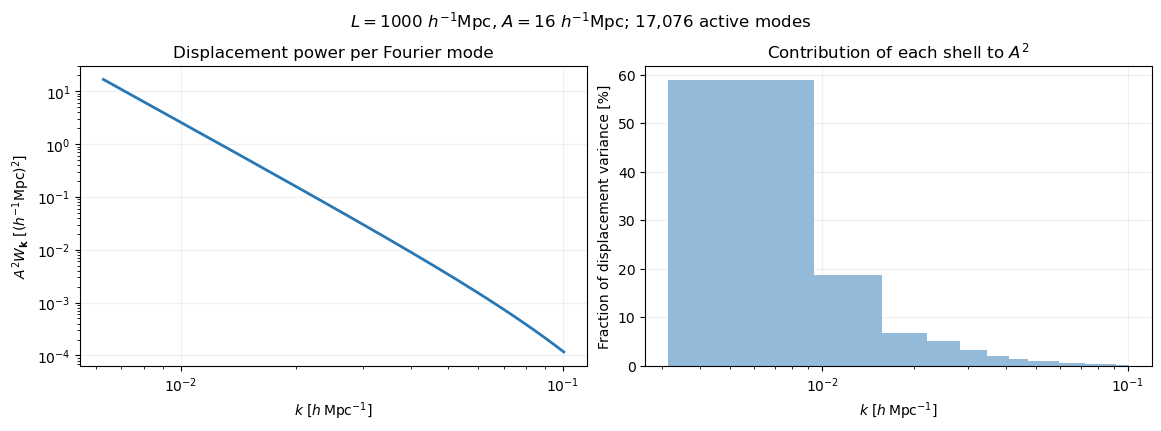

In [1]:
from pathlib import Path
import importlib.util
from IPython.display import display, Markdown
%matplotlib inline
import matplotlib.pyplot as plt
OUT = Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/20261123_intro_PVdisp_L1000_A16')
spec = importlib.util.spec_from_file_location('fiducial_intro_report', Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/20261123_intro_PVdisp_L1000_A16/report_revision/code/intro_fiducial.py'))
report = importlib.util.module_from_spec(spec)
spec.loader.exec_module(report)
fig = report.spectrum_figure(OUT)
display(fig)
plt.close(fig)


## 2. What does helicity mean?

Helical Fourier vectors satisfy $i\mathbf k\times\mathbf e_\pm=\pm k\mathbf e_\pm$. Construct independent Gaussian fields $\mathbf u_\pm$ with unit ensemble RMS, then combine them as
$$\boldsymbol\Psi_{\rm hel}=A\left[\sqrt{\frac{1+\epsilon}{2}}\,\mathbf u_+
+\sqrt{\frac{1-\epsilon}{2}}\,\mathbf u_-\right].$$
$\epsilon=+1$ or $-1$ selects one handedness; $\epsilon=0$ has equal expected power in both. In every case,
$$\sqrt{\mathbb E[\langle|\boldsymbol\Psi_{\rm hel}|^2\rangle]}=A.$$

**One-mode illustration:** $\boldsymbol\Psi_\pm=A(\cos kq_z,\mp\sin kq_z,0)$, with wavelength $L=1000$. The arrows rotate in opposite directions. This illustrates handedness; the random fields below contain the full spectrum from Section 1.


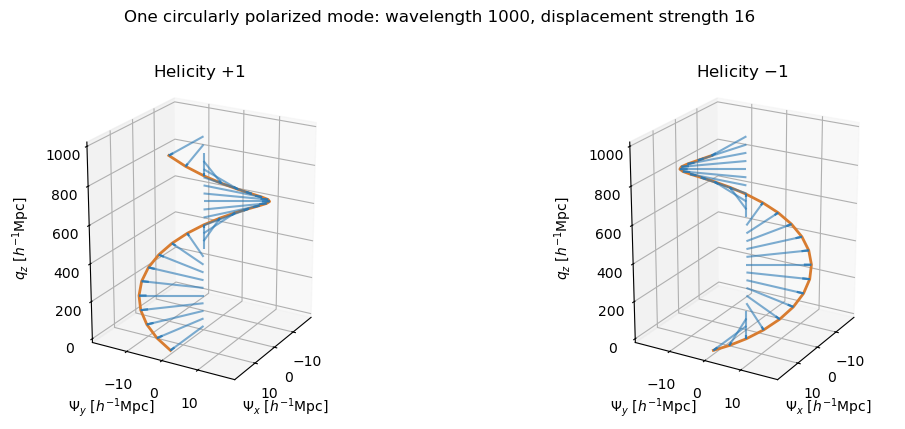

In [2]:
fig = report.helicity_figure(OUT)
display(fig)
plt.close(fig)

## 3. Random-field examples at $A=16$

The same underlying Gaussian draws are used in all three panels. The slice is at $q_z=515.625\ h^{-1}\mathrm{Mpc}$, a plane of the initial particle lattice. Arrows show $(\Psi_{{\rm hel},x},\Psi_{{\rm hel},y})$ at their true coordinate scale; colour shows $\Psi_{{\rm hel},z}$. All panels share the same colour scale.


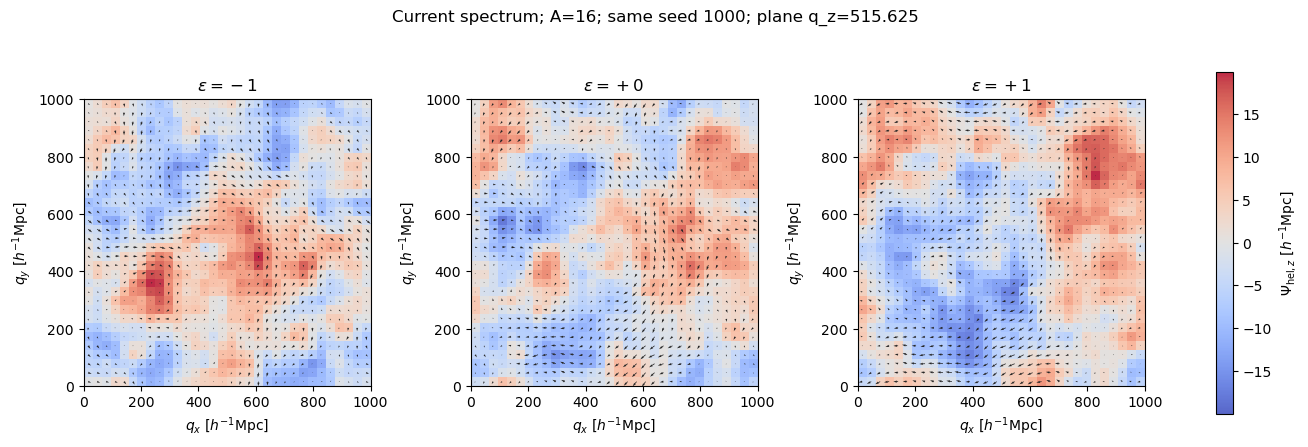

**Measured displacement RMS for this realization** (all 32,768 particles; units $h^{-1}\mathrm{Mpc}$).

| ε | Expected helical RMS $A$ | Measured helical RMS | Measured ZA + helical RMS |
|---:|---:|---:|---:|
| -1 | 16 | 12.524 | 13.032 |
| +0 | 16 | 13.799 | 14.263 |
| +1 | 16 | 14.967 | 15.395 |

$A$ sets the ensemble RMS; a single realization fluctuates. The displacement vector has zero ensemble mean.

In [3]:
fig = report.slice_figure(OUT)
display(fig)
plt.close(fig)
display(Markdown(report.rms_table(OUT)))

## 4. Adding the displacement to the initial conditions

Derive the Zel’dovich approximation (ZA) displacement from the Gaussian density,
$$\boldsymbol\Psi_{\rm ZA}(\mathbf k)=i\mathbf k\,\delta_{\mathbf k}/k^2,$$
then place particles using both fields evaluated at their **initial** lattice positions:
$$\mathbf x(\mathbf q)=\left[\mathbf q+\boldsymbol\Psi_{\rm ZA}(\mathbf q)+\boldsymbol\Psi_{\rm hel}(\mathbf q)\right]\bmod L.$$

The plots track the same 256 particles from a central patch of the initial plane. Gray points show their **ZA-only** positions; coloured points and arrows show the effect of adding the helical displacement at $A=16$. The view is a projection onto $x$–$y$.

The particle spacing is $31.25\ h^{-1}\mathrm{Mpc}$, so $A$ is **0.512 particle spacings**. These are displaced initial conditions; no subsequent gravitational evolution is applied.


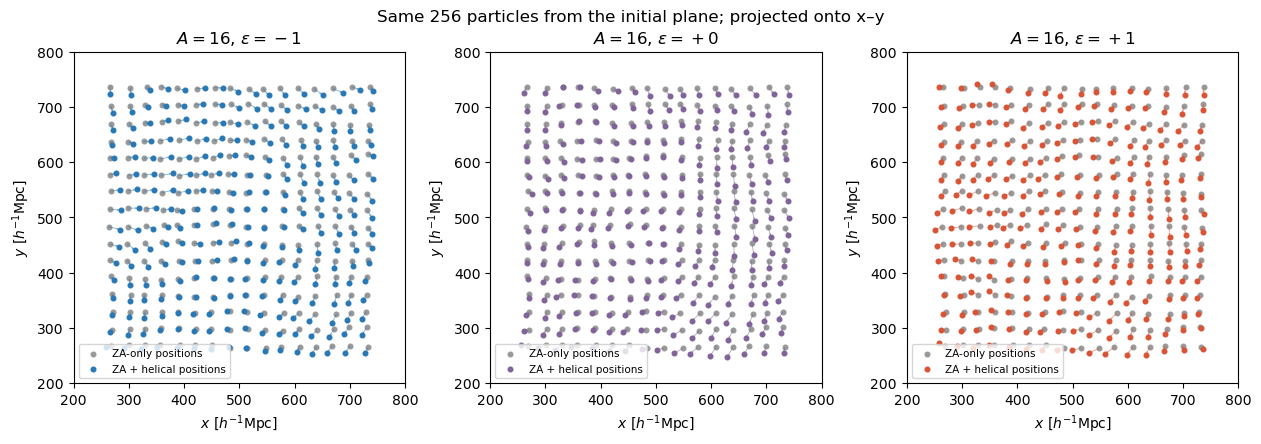

In [4]:
fig = report.particle_figure(OUT)
display(fig)
plt.close(fig)

[Catalogue chirality measurements](field_PVdisp_B.ipynb) · [Density-power response](field_PVdisp_Pk.ipynb) · [Basic PV definitions](basic.ipynb)

[Configuration](saved/20261123_intro_PVdisp_L1000_A16/config.json) · [Plots](saved/20261123_intro_PVdisp_L1000_A16/figures/) · [Example arrays](saved/20261123_intro_PVdisp_L1000_A16/examples.npz) · [Displacement power](saved/20261123_intro_PVdisp_L1000_A16/mode_power.csv) · [RMS table](saved/20261123_intro_PVdisp_L1000_A16/realization_RMS.csv) · [Validation](saved/20261123_intro_PVdisp_L1000_A16/validation/report.json)